# Explaining the Flower Classifier with Grad-CAM

**Author:** Nazeer Idris · Applied Data Science & AI, Breda University of Applied Sciences (Year 1, 2024–25)

This notebook applies **Grad-CAM** (using the [`xplique`](https://github.com/deel-ai/xplique) library) to the final EfficientNetB0 flower classifier from [01_flower_classifier.ipynb](01_flower_classifier.ipynb). Grad-CAM shows which parts of an image the model focused on when it made a prediction, which helps explain why it predicted a certain class.

**Steps**

1. **Import libraries** for loading the model, working with images, plotting and Grad-CAM.
2. **Set paths and class names**: the test folder, the five classes and the 220×220 input size.
3. **Load the model** trained in notebook 01 and create a Grad-CAM explainer.
4. **Load test images**: two random images per class, resized and normalized.
5. **Apply Grad-CAM**: for each image, predict the class, create the heatmap and show it next to the original image with the true label, the predicted label and the confidence.

> The trained model and the dataset are not included in this repository, so this notebook is shown with its saved outputs.

In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from xplique.attributions import GradCAM
from tensorflow.keras.preprocessing import image


In [2]:
TEST_DIR = os.path.join("..", "data", "flowers", "test")
IMAGE_SIZE = (220, 220)
CLASS_NAMES = ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

In [3]:
# Final EfficientNetB0 model saved from notebook 01 (not included in this repository)
model_path = os.path.join("..", "models", "flower_classifier")
model = load_model(model_path)
gradcam = GradCAM(model=model)

In [4]:
def load_test_images(num_images=5):
    images, labels, paths = [], [], []

    for class_idx, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(TEST_DIR, class_name)
        image_files = [f for f in os.listdir(class_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]
        selected_files = np.random.choice(image_files, min(num_images, len(image_files)), replace=False)
        
        for file_name in selected_files:
            img_path = os.path.join(class_dir, file_name)
            img = image.load_img(img_path, target_size=IMAGE_SIZE)
            img_array = image.img_to_array(img) / 255.0
            images.append(img_array)
            labels.append(class_idx)
            paths.append(img_path)

    return np.array(images), np.array(labels), paths


In [5]:
X_test, y_test, img_paths = load_test_images(num_images=2)


Explaining image 1: data/flowers/test/daisy/519880292_7a3a6c6b69.jpg


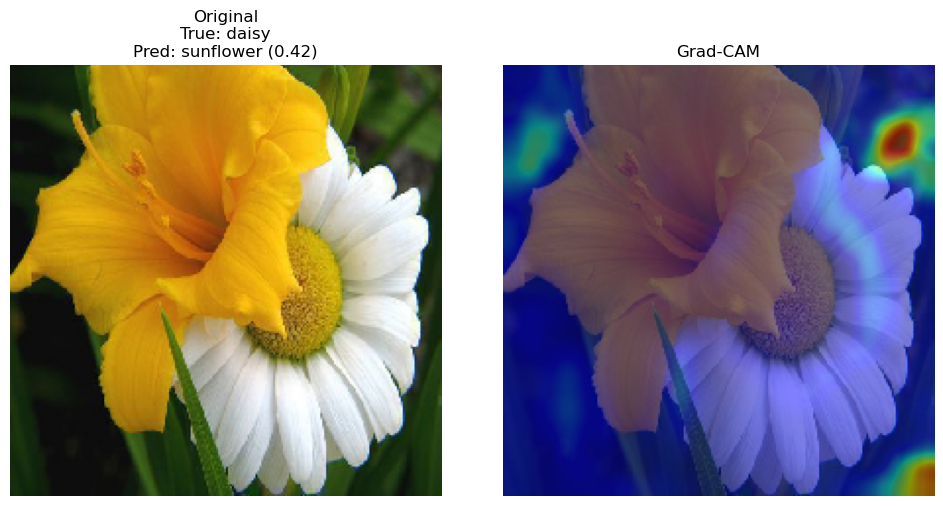

True: daisy
Predicted: sunflower (0.42)
--------------------------------------------------
Explaining image 2: data/flowers/test/daisy/10770585085_4742b9dac3_n.jpg


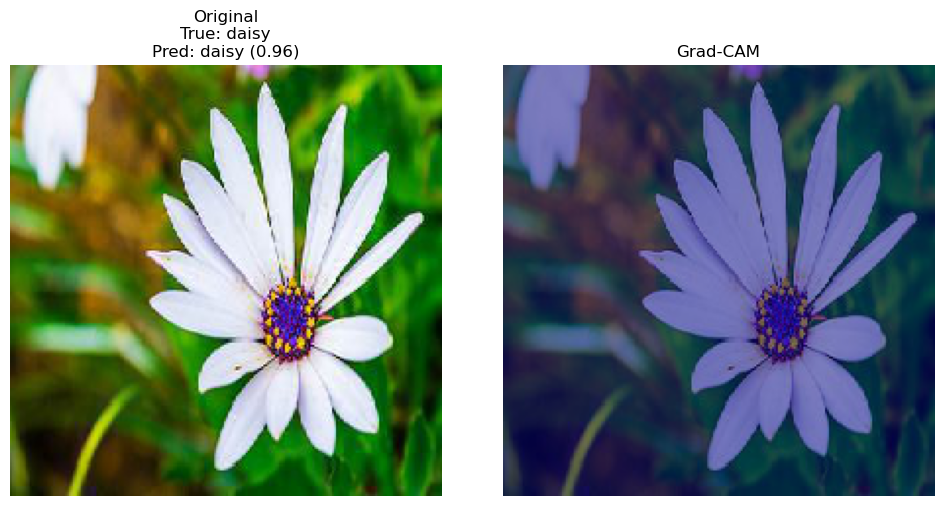

True: daisy
Predicted: daisy (0.96)
--------------------------------------------------
Explaining image 3: data/flowers/test/dandelion/17747738311_5014b1f77f.jpg


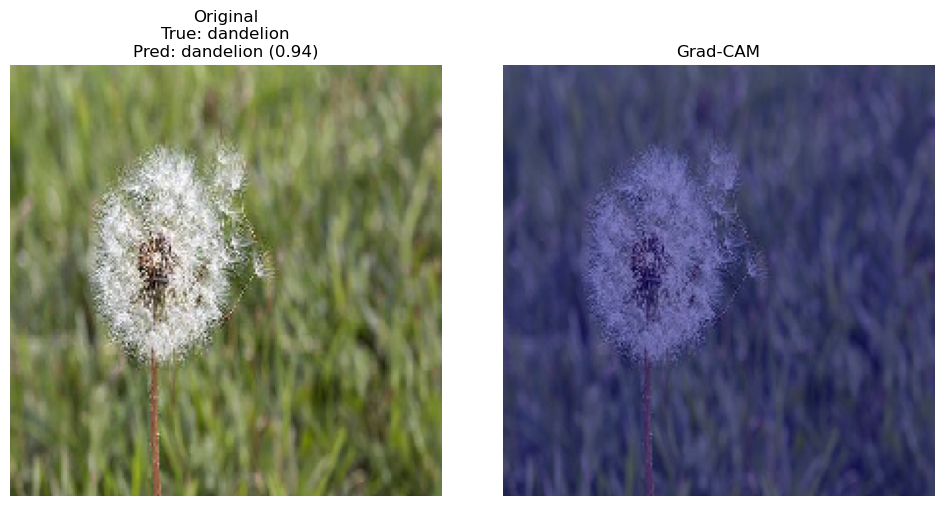

True: dandelion
Predicted: dandelion (0.94)
--------------------------------------------------
Explaining image 4: data/flowers/test/dandelion/7950901292_2dea05f9a2_n.jpg


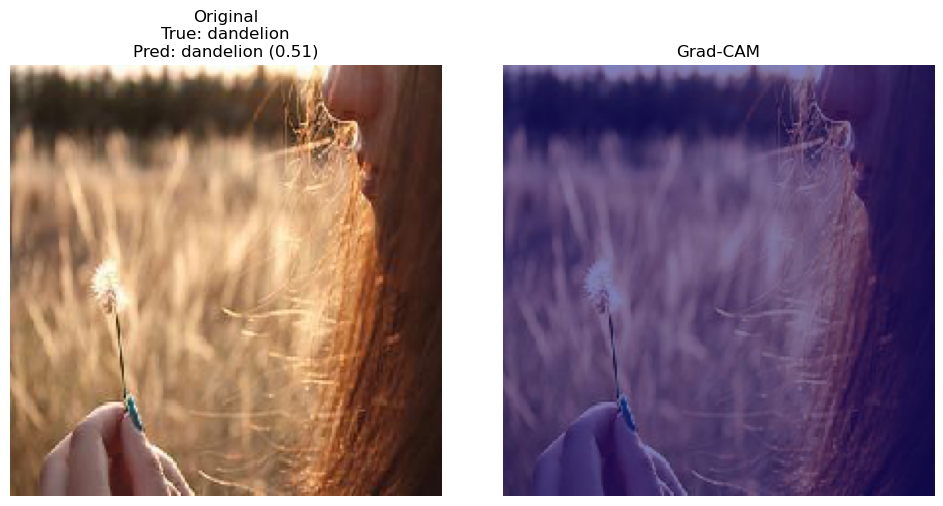

True: dandelion
Predicted: dandelion (0.51)
--------------------------------------------------
Explaining image 5: data/flowers/test/rose/5249566718_6109630c83_m.jpg


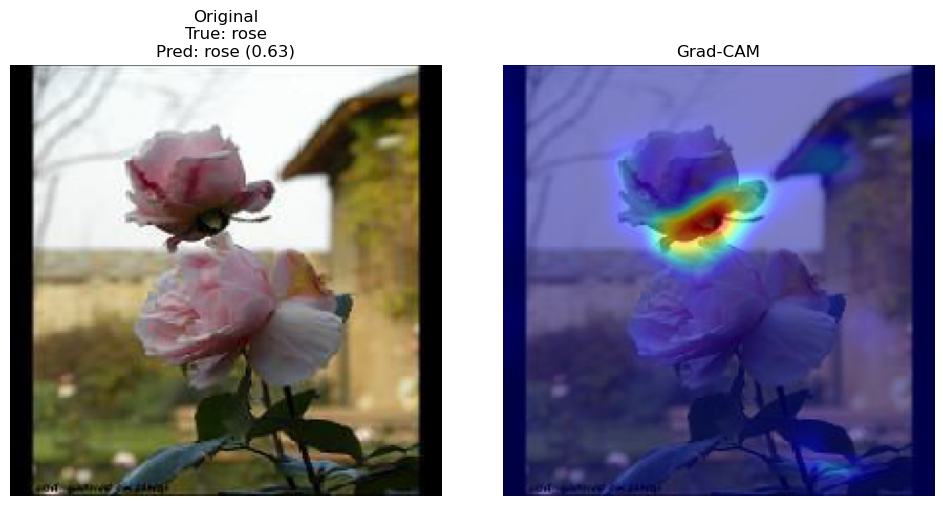

True: rose
Predicted: rose (0.63)
--------------------------------------------------
Explaining image 6: data/flowers/test/rose/5002447916_8a7b7b689a_n.jpg


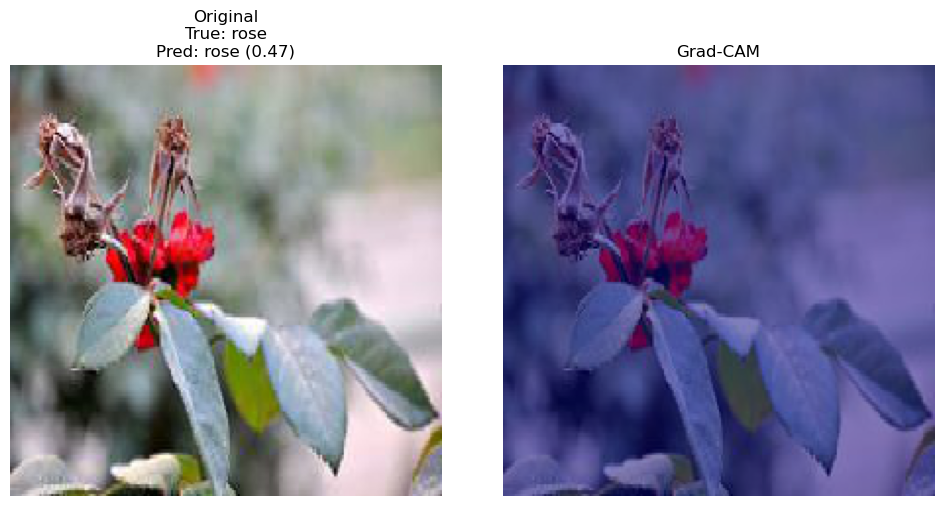

True: rose
Predicted: rose (0.47)
--------------------------------------------------
Explaining image 7: data/flowers/test/sunflower/4869189730_f47c124cda_n.jpg


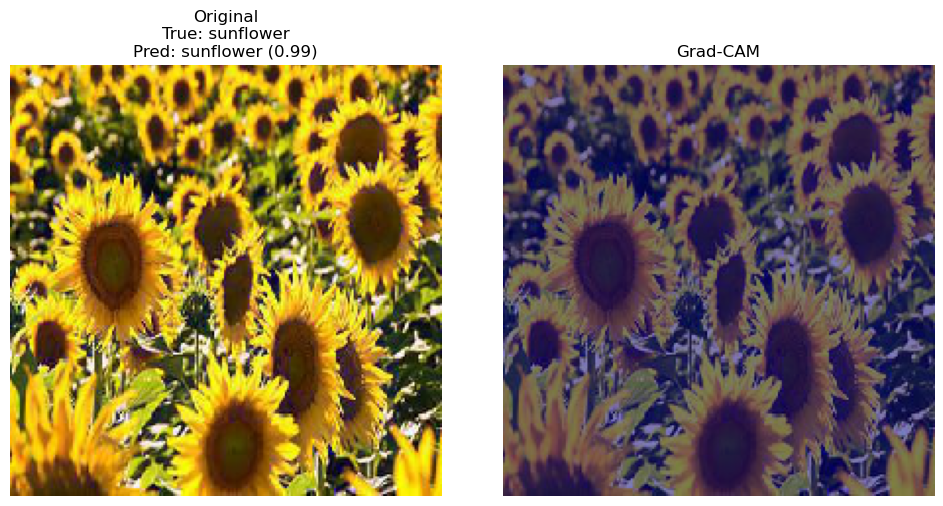

True: sunflower
Predicted: sunflower (0.99)
--------------------------------------------------
Explaining image 8: data/flowers/test/sunflower/4191299785_a4faca9b74_n.jpg


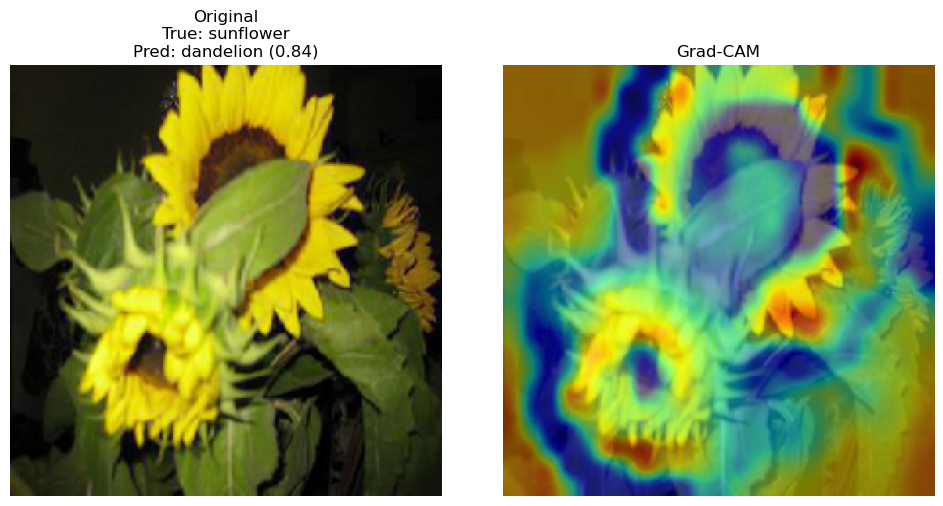

True: sunflower
Predicted: dandelion (0.84)
--------------------------------------------------
Explaining image 9: data/flowers/test/tulip/391477275_7c2f50a1a7_m.jpg


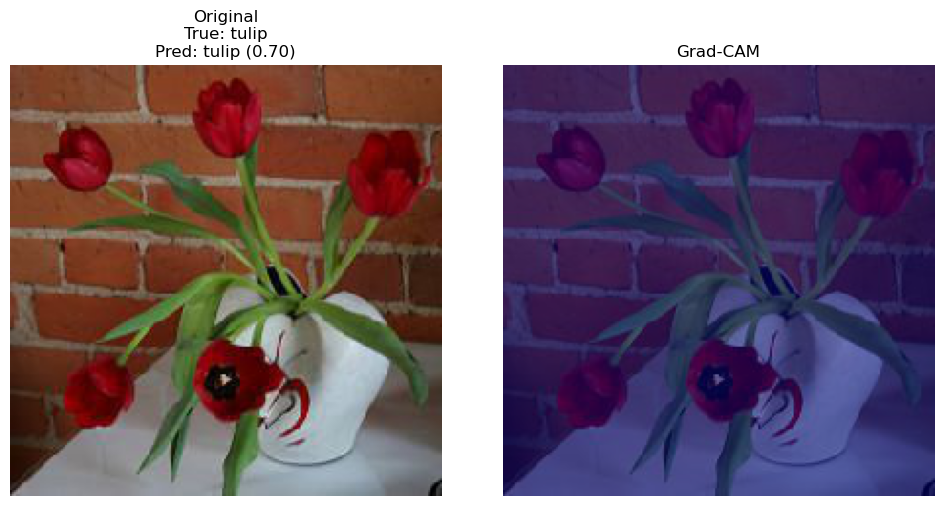

True: tulip
Predicted: tulip (0.70)
--------------------------------------------------
Explaining image 10: data/flowers/test/tulip/8511683706_4173683d45_m.jpg


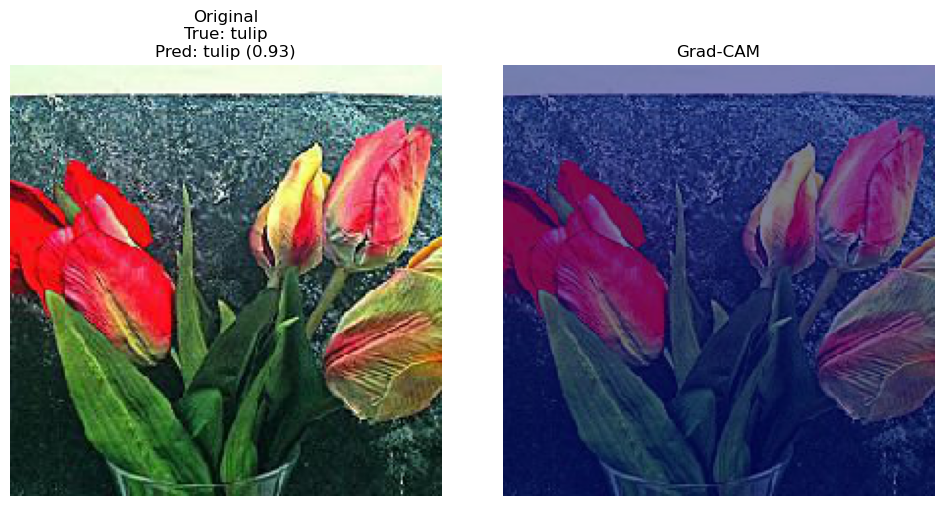

True: tulip
Predicted: tulip (0.93)
--------------------------------------------------


In [6]:
for i in range(len(X_test)):
    print(f"Explaining image {i+1}: {img_paths[i]}")
    
    sample_image = X_test[i]
    sample_image_batch = np.expand_dims(sample_image, axis=0)

    preds = model.predict(sample_image_batch, verbose=0)
    predicted_class = np.argmax(preds[0])
    prediction_confidence = preds[0][predicted_class]

    explanations = gradcam.explain(sample_image_batch, targets=[predicted_class])

    plt.figure(figsize=(10, 5))
    
    plt.subplot(1, 2, 1)
    plt.imshow(sample_image)
    plt.title(f"Original\nTrue: {CLASS_NAMES[y_test[i]]}\nPred: {CLASS_NAMES[predicted_class]} ({prediction_confidence:.2f})")
    plt.axis("off")
    
    plt.subplot(1, 2, 2)
    plt.imshow(sample_image)
    plt.imshow(explanations[0], cmap='jet', alpha=0.5)
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"True: {CLASS_NAMES[y_test[i]]}")
    print(f"Predicted: {CLASS_NAMES[predicted_class]} ({prediction_confidence:.2f})")
    print("-" * 50)


## Summary

Grad-CAM makes the model's decisions more transparent. It shows which areas of an image the model used for its prediction, which makes it easier to trust the model or to find what needs improving.

In this sample, 8 of the 10 test images were classified correctly. The two mistakes are the same similar-looking-flower confusions found in the error analysis in notebook 01:

- a **daisy predicted as a sunflower**: the image also contains a large yellow flower;
- a **sunflower predicted as a dandelion**: the heatmap is spread over the dark background rather than the flower heads.

For most of the other images, the heatmap is almost flat, so Grad-CAM gives little information there.

**Next step:** in this notebook the images are scaled to [0, 1] before prediction, but the EfficientNetB0 model in notebook 01 was trained on raw [0, 255] pixel values (EfficientNet does its own rescaling inside the model). Feeding the images in the same range as during training would likely give sharper heatmaps and higher confidence scores.